# Clase 4: Redes neuronales recurrentes

En las diapositivas vimos por qué el orden de las palabras importa y qué arquitecturas se propusieron para representarlo: la red recurrente, la LSTM y la GRU, y el encoder–decoder. En este notebook las usamos como se usan en la práctica: un clasificador de texto completo, comparado con un baseline; cómo elegir entre una red y otra; un etiquetador que da una salida por palabra, y un traductor.

Al final hay ejercicios propuestos: entrenar ustedes lo que aquí cargamos ya entrenado y algunos experimentos que toman más tiempo.

**Objetivos de la clase**

- Entrenar un clasificador recurrente en PyTorch de punta a punta (vocabulario, relleno, entrenamiento, evaluación, guardado) y compararlo con un baseline TF-IDF.
- Elegir entre TF-IDF y una red recurrente según el puntaje, la cantidad de datos y el costo.
- Distinguir tres formas de usar una red recurrente: una salida por texto, una salida por palabra y una secuencia de salida.
- Explicar con un ejemplo por qué un encoder–decoder sin atención pierde calidad con oraciones largas.

## 0. Preparación

PyTorch, pandas y scikit-learn vienen instalados en Colab. Usamos las reseñas de Amazon de la clase 3. Los modelos preentrenados (un etiquetador y un traductor) se descargan del repositorio del curso cuando se usan. La carga de los datos tarda unos segundos.

In [1]:
import random
import re
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pd.set_option("display.precision", 2)
pd.set_option("display.max_colwidth", 120)
torch.manual_seed(0)
URL_MODELOS = ("https://raw.githubusercontent.com/dccuchile/CC66Q/main/"
               "tutorials/modelos/")

In [2]:
URL = ("https://huggingface.co/datasets/mteb/amazon_reviews_multi/"
       "resolve/main/es/")
train = pd.read_json(URL + "train.jsonl", lines=True)
test = pd.read_json(URL + "test.jsonl", lines=True)
train.shape, test.shape

((200000, 4), (5000, 4))

## 1. Un clasificador de reseñas, de punta a punta

Armemos el flujo completo con las reseñas de la clase 3: positiva si tiene 4 o 5 estrellas, negativa si tiene 1 o 2 (dejamos fuera las de 3). Para que el entrenamiento tome pocos minutos, usamos 20.000 reseñas de hasta 60 palabras y separamos 2.000 para validación: con ellas tomamos las decisiones, y el conjunto de prueba queda para el final.

In [3]:
def tokenizar(texto):
    """Devuelve las palabras en minúsculas."""
    return re.findall(r"\w+", texto.lower())


def preparar(df):
    """Deja las reseñas de 1 a 60 palabras con 1, 2, 4 o 5 estrellas."""
    df = df[df["label"] != 2].copy()
    df["tokens"] = df["text"].map(tokenizar)
    df["positiva"] = (df["label"] >= 3).astype(int)
    return df[df["tokens"].str.len().between(1, 60)]


resenas = preparar(train).sample(20_000, random_state=0)
validacion, entreno = resenas[:2_000], resenas[2_000:]
prueba = preparar(test)
len(entreno), len(validacion), len(prueba), round(entreno["positiva"].mean(), 2)

(18000, 2000, 3644, np.float64(0.51))

### 1.1 Primero, un baseline

Antes de entrenar una red conviene saber qué puntaje se logra sin ella. El baseline de la clase 2 es TF-IDF con regresión logística, que se entrena en segundos. Probamos también TF-IDF con bigramas, que capturan el orden local.

In [4]:
tfidf = TfidfVectorizer(min_df=2)
logistica = LogisticRegression(max_iter=2000).fit(
    tfidf.fit_transform(entreno["text"]), entreno["positiva"])
tfidf2 = TfidfVectorizer(min_df=2, ngram_range=(1, 2))
logistica2 = LogisticRegression(max_iter=2000).fit(
    tfidf2.fit_transform(entreno["text"]), entreno["positiva"])

pd.Series({
    "TF-IDF": logistica.score(tfidf.transform(validacion["text"]),
                              validacion["positiva"]),
    "TF-IDF con bigramas": logistica2.score(
        tfidf2.transform(validacion["text"]), validacion["positiva"]),
}, name="accuracy de validación")

TF-IDF                 0.91
TF-IDF con bigramas    0.91
Name: accuracy de validación, dtype: float64

### 1.2 Del texto a tensores

Ese es el puntaje que la red tiene que superar. Para entrenarla hay que convertir el texto en números: `nn.Embedding` busca vectores por número, así que cada palabra del vocabulario recibe un id. El 0 queda reservado para rellenar las reseñas cortas y el 1 para las palabras que no están en el vocabulario. En la clase 3 usamos embeddings ya entrenados; aquí la tabla parte al azar y se aprende junto con el resto (con `nn.Embedding.from_pretrained` se puede cargar una tabla entrenada y decidir si se congela o se sigue ajustando).

In [5]:
def crear_vocabulario(listas, minimo=3):
    """Asigna un id a cada palabra que aparece al menos `minimo` veces."""
    frecuencias = Counter(palabra for tokens in listas for palabra in tokens)
    vocab = {"<pad>": 0, "<unk>": 1}
    for palabra, n in frecuencias.most_common():
        if n >= minimo:
            vocab[palabra] = len(vocab)
    return vocab


vocab = crear_vocabulario(entreno["tokens"])
len(vocab)

7583

In [6]:
def codificar(tokens, vocab=vocab):
    """Devuelve los ids de los tokens; 1 para los desconocidos."""
    return torch.tensor([vocab.get(palabra, 1) for palabra in tokens])


def lote(df, etiqueta="positiva", vocab=vocab):
    """Devuelve la matriz de ids con relleno, los largos y las etiquetas."""
    X = nn.utils.rnn.pad_sequence([codificar(t, vocab) for t in df["tokens"]], batch_first=True)
    return X, torch.tensor(df["tokens"].str.len().values), torch.tensor(df[etiqueta].values)


datos_entreno, datos_val, datos_prueba = lote(entreno), lote(validacion), lote(prueba)
datos_entreno[0].shape, datos_entreno[0][0, :12]

(torch.Size([18000, 60]),
 tensor([  18,    8, 1198,    7, 2882,    6,   83,  135,   60,  763,   13, 1519]))

Las reseñas cortas quedan rellenas con ceros hasta el largo de la más larga.

**Antes de ejecutar:** si a una reseña le agregamos ceros de relleno al final, ¿cambia el último estado de una GRU?

In [7]:
torch.manual_seed(0)
gru = nn.GRU(8, 8, batch_first=True)
emb = nn.Embedding(len(vocab), 8, padding_idx=0)
ids = codificar(tokenizar("El producto llegó roto"))
con_relleno = torch.cat([ids, torch.zeros(5, dtype=torch.long)])

with torch.no_grad():
    _, h_sin = gru(emb(ids[None]))
    _, h_con = gru(emb(con_relleno[None]))
    empacada = nn.utils.rnn.pack_padded_sequence(emb(con_relleno[None]), torch.tensor([len(ids)]),
                                                 batch_first=True)
    _, h_empacada = gru(empacada)

(h_con - h_sin).norm().item(), (h_empacada - h_sin).norm().item()

(0.7389665842056274, 0.0)

Cambia. Aunque el vector del relleno sea cero, la GRU sigue actualizando el estado en cada posición, y el «último estado» pasa a ser el del último cero, no el de la última palabra. `pack_padded_sequence` le dice a la red el largo real de cada reseña, y el estado final vuelve a ser el de la última palabra. Por eso guardamos los largos.

El modelo tiene tres capas: la tabla de embeddings, la GRU y una capa lineal que convierte el último estado en dos puntajes, uno por clase.

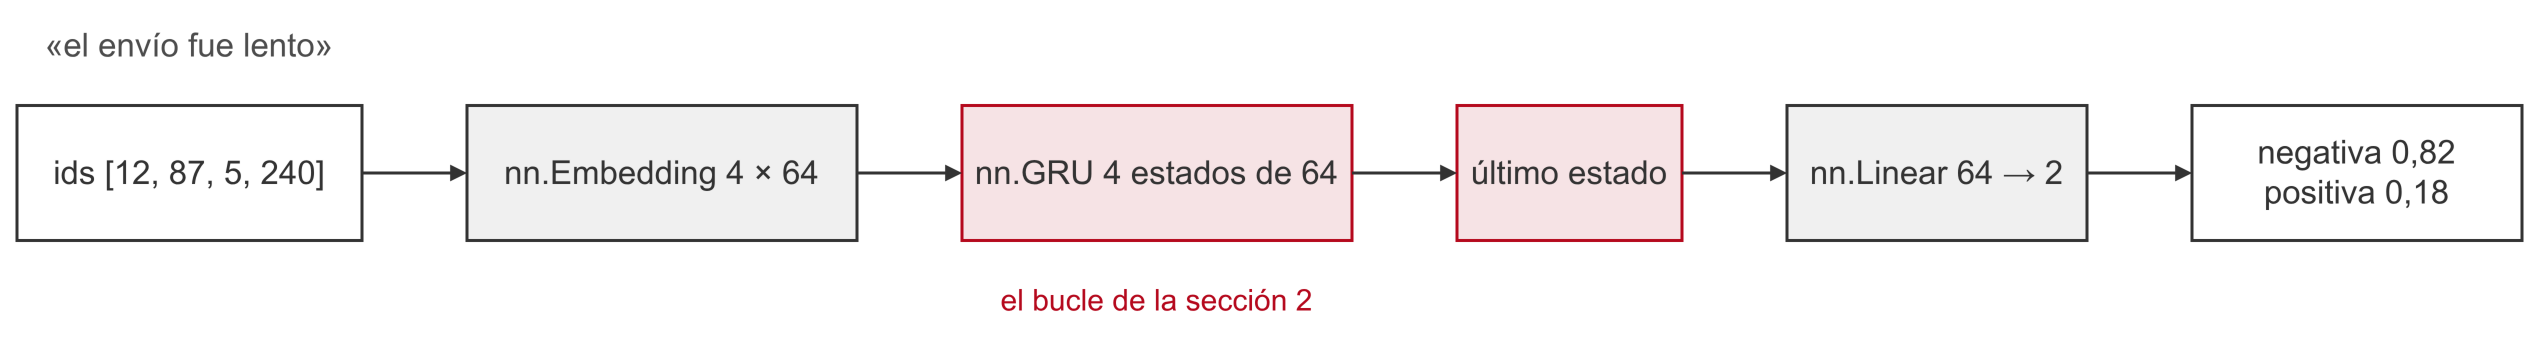

In [8]:
class Clasificador(nn.Module):
    def __init__(self, n_palabras, celda=nn.GRU, d=64, h=64, salidas=2):
        super().__init__()
        self.embedding = nn.Embedding(n_palabras, d, padding_idx=0)
        self.recurrente = celda(d, h, batch_first=True)
        self.salida = nn.Linear(h, salidas)

    def forward(self, X, largos):
        E = self.embedding(X)
        E = nn.utils.rnn.pack_padded_sequence(E, largos, batch_first=True, enforce_sorted=False)
        _, h = self.recurrente(E)  # h: el último estado
        if isinstance(h, tuple):   # la LSTM devuelve (estado, memoria)
            h = h[0]
        return self.salida(h[-1])

El ciclo de entrenamiento es el del módulo de deep learning: lotes de 64 reseñas, entropía cruzada y Adam. Después de cada época medimos la accuracy en validación y guardamos los pesos de la mejor época, una forma simple de detención temprana (early stopping). Las tres épocas tardan un par de minutos en CPU.

In [9]:
def accuracy(modelo: nn.Module, datos: tuple) -> float:
    """Devuelve la fracción de aciertos del modelo en los datos."""
    X, L, y = datos
    modelo.eval()
    with torch.no_grad():
        return (modelo(X, L).argmax(1) == y).float().mean().item()


def entrenar(modelo: nn.Module, datos_entreno: tuple, datos_val: tuple,
             epocas: int = 3) -> nn.Module:
    """Entrena el modelo y deja los pesos de su mejor época en validación."""
    X, L, y = datos_entreno
    optimizador = torch.optim.Adam(modelo.parameters(), lr=2e-3)
    perdida = nn.CrossEntropyLoss()
    mejor = 0
    for epoca in range(epocas):
        modelo.train()
        for i in torch.randperm(len(X)).split(64):
            optimizador.zero_grad()
            perdida(modelo(X[i], L[i]), y[i]).backward()
            optimizador.step()
        acc = accuracy(modelo, datos_val)
        print(f"época {epoca + 1}: accuracy de validación {acc:.3f}")
        if acc > mejor:
            mejor = acc
            pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
    modelo.load_state_dict(pesos)
    return modelo


torch.manual_seed(0)
modelo = entrenar(Clasificador(len(vocab)), datos_entreno, datos_val)

época 1: accuracy de validación 0.891


época 2: accuracy de validación 0.899


época 3: accuracy de validación 0.904


### 1.3 Evaluación

Recién ahora usamos el conjunto de prueba, una sola vez, para los tres modelos.

**Antes de ejecutar:** ¿supera la GRU al baseline?

In [10]:
pd.Series({
    "TF-IDF": logistica.score(tfidf.transform(prueba["text"]),
                              prueba["positiva"]),
    "TF-IDF con bigramas": logistica2.score(tfidf2.transform(prueba["text"]),
                                            prueba["positiva"]),
    "GRU": accuracy(modelo, datos_prueba),
}, name="accuracy de prueba").round(3)

TF-IDF                 0.92
TF-IDF con bigramas    0.92
GRU                    0.92
Name: accuracy de prueba, dtype: float64

Los tres llegan a 0,92: con estas reseñas, la GRU no supera al baseline. El puntaje tampoco dice dónde se equivoca. La matriz de confusión cuenta los aciertos y los errores de cada clase; después miramos los errores en que la GRU estaba más segura.

In [11]:
X, L, y = datos_prueba
with torch.no_grad():
    p_positiva = torch.softmax(modelo(X, L), 1)[:, 1].numpy()
resultado = prueba.assign(p_positiva=p_positiva)
pd.crosstab(resultado["positiva"], resultado["p_positiva"] > 0.5,
            rownames=["real"], colnames=["predice positiva"])

predice positiva,False,True
real,,
0,1600,185
1,118,1741


In [12]:
acierto = (resultado["p_positiva"] > 0.5) == (resultado["positiva"] == 1)
errores = resultado[~acierto]
seguros = (errores["p_positiva"] - 0.5).abs().nlargest(5).index
errores.loc[seguros, ["text", "positiva", "p_positiva"]]

,text,positiva,p_positiva
1733,"Buena calidad, falla la talla\n\nTallaje un poco grande, compré una L que es mi talla y me sobra de cintura. Por lo ...",0,9.99e-01
3939,"Producto bien, embalaje mal, muy mal.\n\nEl producto en sí bien porque ya tenía otro y se de qué va el tema, pero mu...",1,3.98e-03
3144,No están mal.\n\nEs un producto que da lo que vale. A mí me costaron 30 en su momento y tampoco se pueden esperar mi...,1,5.76e-03
1421,"Grosor fino\n\nEl producto es tal cual, aunque con un grosor inferior al esperado, pero es util",0,9.93e-01
1076,El producto es bueno Adactador coriente falla\n\nFalla el adaptador de corriente Reiniciándose muy seguido,0,9.93e-01


Los errores más seguros son reseñas mixtas. «Buena calidad, falla la talla» tiene 1 o 2 estrellas y la GRU la da por positiva; «Producto bien, embalaje mal, muy mal» tiene 4 o 5 y la da por negativa. En «No están mal», la negación da vuelta el sentido de «mal». En varias, las estrellas no coinciden con lo que dice el título. Revisar los errores así ayuda a decidir el paso siguiente: conseguir más ejemplos de ese tipo, cambiar de modelo o aceptar que la tarea tiene un techo.

### 1.4 El orden

Dos reseñas con las mismas palabras, donde el veredicto está en la cláusula después de «pero». Para TF-IDF con unigramas son el mismo vector.

**Antes de ejecutar:** ¿la GRU les da el mismo puntaje?

In [13]:
def predecir(texto):
    """Devuelve la probabilidad de reseña positiva y la fracción de palabras conocidas."""
    tokens = tokenizar(texto)
    modelo.eval()
    with torch.no_grad():
        p = torch.softmax(modelo(codificar(tokens)[None], torch.tensor([len(tokens)])), 1)[0, 1]
    conocidas = sum(palabra in vocab for palabra in tokens) / len(tokens)
    return round(p.item(), 2), round(conocidas, 2)


par = ["El envío fue lento, pero el producto es excelente",
       "El producto es excelente, pero el envío fue lento"]
for resena in par:
    print(predecir(resena), logistica.predict_proba(tfidf.transform([resena]))[0, 1].round(2), resena)

(0.94, 1.0) 0.43 El envío fue lento, pero el producto es excelente
(0.78, 1.0) 0.43 El producto es excelente, pero el envío fue lento


TF-IDF da el mismo número a las dos, como tiene que ser. La GRU da dos números distintos y prefiere la reseña que termina con «excelente».

El clasificador solo mira el último estado, pero la GRU calcula un estado después de cada palabra. Si le aplicamos la capa de salida a cada uno, vemos qué opinaría el modelo si la reseña terminara ahí.

**Antes de ejecutar:** en «El envío fue lento, pero el producto es excelente», ¿en qué palabra cambia de opinión?

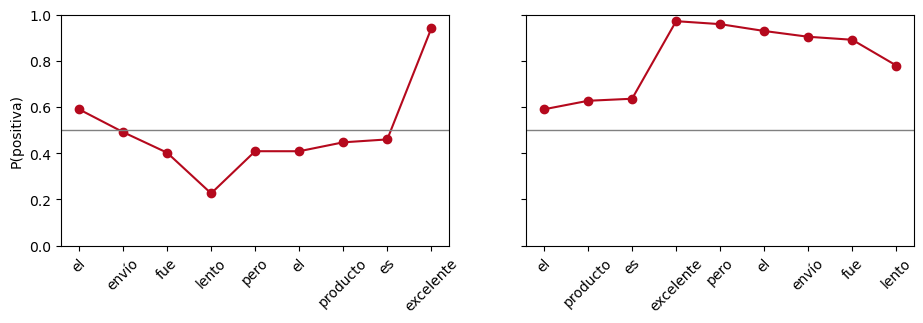

In [14]:
def lectura(texto):
    """Devuelve la probabilidad de reseña positiva después de cada palabra."""
    tokens = tokenizar(texto)
    with torch.no_grad():
        H, _ = modelo.recurrente(modelo.embedding(codificar(tokens)[None]))
        p = torch.softmax(modelo.salida(H[0]), 1)[:, 1]
    return pd.Series(p.numpy(), index=tokens)


fig, ejes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for eje, reseña in zip(ejes, par):
    p = lectura(reseña)
    eje.plot(range(len(p)), p.values, marker="o", color="#B5091D")
    eje.set_xticks(range(len(p)), p.index, rotation=45)
    eje.axhline(0.5, color="#808080", lw=1)
ejes[0].set_ylabel("P(positiva)")
ejes[0].set_ylim(0, 1);

La probabilidad baja con «lento» y sube con «excelente»; en la otra reseña, al revés. El estado se actualiza con cada palabra, y en estas dos reseñas la última cláusula pesa más, aunque las dos quedan sobre 0,5. Esto muestra que el modelo es sensible al orden, no que entienda el discurso. Prueben con «No es malo» o con una negación larga.

Ahora una reseña escrita en el chat. El segundo número es la fracción de sus palabras que el modelo conoce: las desconocidas no le aportan nada.

In [15]:
resena = "Llegó en dos días y la calidad es mejor de lo que esperaba por ese precio"

predecir(resena)

(0.18, 1.0)

En nuestra ejecución, esta reseña positiva sale 0,18: el modelo se equivoca, aunque conoce todas sus palabras.

### 1.5 Guardar el modelo y usarlo

Para usar el modelo fuera de este notebook hay que guardar los pesos y también el vocabulario: sin la tabla palabra → id, los pesos no sirven. Al predecir, `eval()` desactiva lo que solo se usa al entrenar (como el dropout) y `torch.inference_mode()` evita calcular lo necesario para el gradiente.

In [16]:
torch.save({"pesos": modelo.state_dict(), "vocab": vocab}, "clasificador_resenas.pt")

guardado = torch.load("clasificador_resenas.pt")
cargado = Clasificador(len(guardado["vocab"]))
cargado.load_state_dict(guardado["pesos"])
cargado.eval()
with torch.inference_mode():
    ids = codificar(tokenizar("No funciona, lo devolví"), guardado["vocab"])
    print(torch.softmax(cargado(ids[None], torch.tensor([len(ids)])), 1))

tensor([[0.9819, 0.0181]])


## 2. ¿Qué red y cuándo?

En las diapositivas vimos que la red recurrente simple pierde una pista lejana. Por eso en la práctica se usa una GRU o una LSTM; en nuestro clasificador se cambia con un argumento, `Clasificador(len(vocab), nn.LSTM)`.

Además del puntaje, en un sistema real importan el tamaño del modelo y cuánto tarda en predecir. Comparemos la GRU con TF-IDF en las reseñas de prueba. Como una sola medición de tiempo varía mucho, `%timeit` la repite y nos quedamos con la más rápida (`.best`).

In [17]:
t_gru = %timeit -o -q accuracy(modelo, datos_prueba)
t_tfidf = %timeit -o -q logistica.predict(tfidf.transform(prueba["text"]))

pd.DataFrame({
    "parámetros": [sum(p.numel() for p in modelo.parameters()),
                   logistica.coef_.size + 1],
    "segundos para predecir la prueba": [t_gru.best, t_tfidf.best],
}, index=["GRU", "TF-IDF"])

,parámetros,segundos para predecir la prueba
GRU,510402,0.04
TF-IDF,10108,0.02


La GRU tiene unas 50 veces más parámetros que la regresión logística y, en nuestras ejecuciones, tardó entre 2 y 4 veces más en predecir las 3.644 reseñas de prueba, aun sin contar la tokenización. Entrenarla tomó alrededor de un minuto en CPU, contra unos 3 segundos para las dos regresiones logísticas. Para el mismo puntaje, en un sistema real convendría TF-IDF: es más chico y más rápido.

En el ejercicio 6 entrenamos las tres celdas con la misma configuración. En prueba, la RNN simple llega a 0,80 y la GRU y la LSTM, a 0,92; la GRU tiene menos parámetros que la LSTM. La red recurrente se justifica cuando el orden cambia la respuesta, como en el par con «pero», y hay datos suficientes. Desde la clase 5, la opción habitual es partir de un modelo preentrenado.

### Con pocos datos

Con los tweets de la Tarea 1 (odio, incivilidad y normal; unos 12.000) el resultado se da vuelta. Con la misma GRU y la misma partición para los dos modelos (código en el ejercicio 2), en nuestra ejecución:

| | accuracy | macro-F1 |
|---|---|---|
| GRU | 0,74 | 0,72 |
| TF-IDF | 0,77 | 0,75 |

Usamos también macro-F1 porque las clases no están balanceadas: es el promedio del F1 de cada clase, así que «odio», la menos frecuente, pesa lo mismo que las otras. Con estos datos y esta configuración, la GRU entrenada desde cero perdió. Una explicación posible es que aprende el vector de cada palabra con solo 10.000 tweets, en los que muchas palabras aparecen dos o tres veces, mientras que TF-IDF no necesita aprenderlos. Antes de entrenar una red, conviene tener un baseline simple con el que compararla.

## 3. Una salida por palabra

Para clasificar usamos solo el último estado. Si usamos todos los estados, la red da una salida por palabra: su categoría gramatical, o si es parte del nombre de una persona, una organización o un lugar (reconocimiento de entidades, named entity recognition o NER, la misma estructura con otras etiquetas). Para etiquetar una palabra ayudan también las que vienen después, así que se usa una red bidireccional (bidirectional): lee la oración de izquierda a derecha y de derecha a izquierda, y junta los dos estados de cada palabra.

Esta red la entrenamos antes: diez épocas sobre las 14.186 oraciones del corpus Spanish-GSD de Universal Dependencies (licencia CC BY-SA 4.0), etiquetadas a mano. Acierta la categoría del 93 % de las palabras del conjunto de prueba.

In [18]:
class Etiquetador(nn.Module):
    def __init__(self, n_palabras, n_categorias, d=64, h=64):
        super().__init__()
        self.embedding = nn.Embedding(n_palabras, d, padding_idx=0)
        self.recurrente = nn.GRU(d, h, batch_first=True, bidirectional=True)
        self.salida = nn.Linear(2 * h, n_categorias)

    def forward(self, X):
        H, _ = self.recurrente(self.embedding(X))
        return self.salida(H)  # una salida por palabra


guardado = torch.hub.load_state_dict_from_url(URL_MODELOS + "4-etiquetador-ud.pt", weights_only=True)
vocab_ud = {palabra: i for i, palabra in enumerate(guardado["vocab"])}
categorias = guardado["categorias"]
etiquetador = Etiquetador(len(vocab_ud), len(categorias), guardado["d"], guardado["h"])
etiquetador.load_state_dict({k: v.float() for k, v in guardado["pesos"].items()})
etiquetador.eval()
categorias[1:]

['ADJ',
 'ADP',
 'ADV',
 'AUX',
 'CCONJ',
 'DET',
 'INTJ',
 'NOUN',
 'NUM',
 'PART',
 'PRON',
 'PROPN',
 'PUNCT',
 'SCONJ',
 'SYM',
 'VERB',
 'X']

**Antes de ejecutar:** ¿qué categoría le da al primer «vino» de «Vino ayer y trajo vino»? ¿Y al segundo?

In [19]:
def etiquetar(texto):
    """Devuelve la categoría que la red asigna a cada palabra."""
    tokens = tokenizar(texto)
    with torch.no_grad():
        ids = etiquetador(codificar(tokens, vocab_ud)[None]).argmax(-1)[0]
    return pd.Series([categorias[i] for i in ids.tolist()], index=tokens)


for oracion in ["Vino ayer y trajo vino", "El vino estaba frío", "Llama a tu madre"]:
    print(" ".join(f"{p}/{c}" for p, c in etiquetar(oracion).items()))

vino/VERB ayer/ADV y/CCONJ trajo/AUX vino/NOUN
el/DET vino/NOUN estaba/AUX frío/ADJ
llama/VERB a/ADP tu/DET madre/NOUN


El primer «vino» es verbo y el último, sustantivo: la misma palabra, con la misma fila de la tabla de embeddings, recibe etiquetas distintas según sus vecinas. Las categorías son las de Universal Dependencies: VERB verbo, NOUN sustantivo, AUX verbo auxiliar, ADP preposición, DET determinante. Como es bidireccional, necesita la oración completa antes de etiquetar; una red que lee solo hacia adelante, en cambio, puede procesar el texto a medida que llega.

## 4. Una secuencia de otro largo: encoder–decoder

Clasificar da una salida por texto y etiquetar, una por palabra. Traducir pide una secuencia de salida de otro largo. El encoder–decoder de Sutskever et al. (2014) y Cho et al. (2014) usa dos redes recurrentes: el encoder lee la entrada, y su último estado es lo único que recibe el decoder, que escribe la salida símbolo por símbolo, cada uno a partir del anterior.

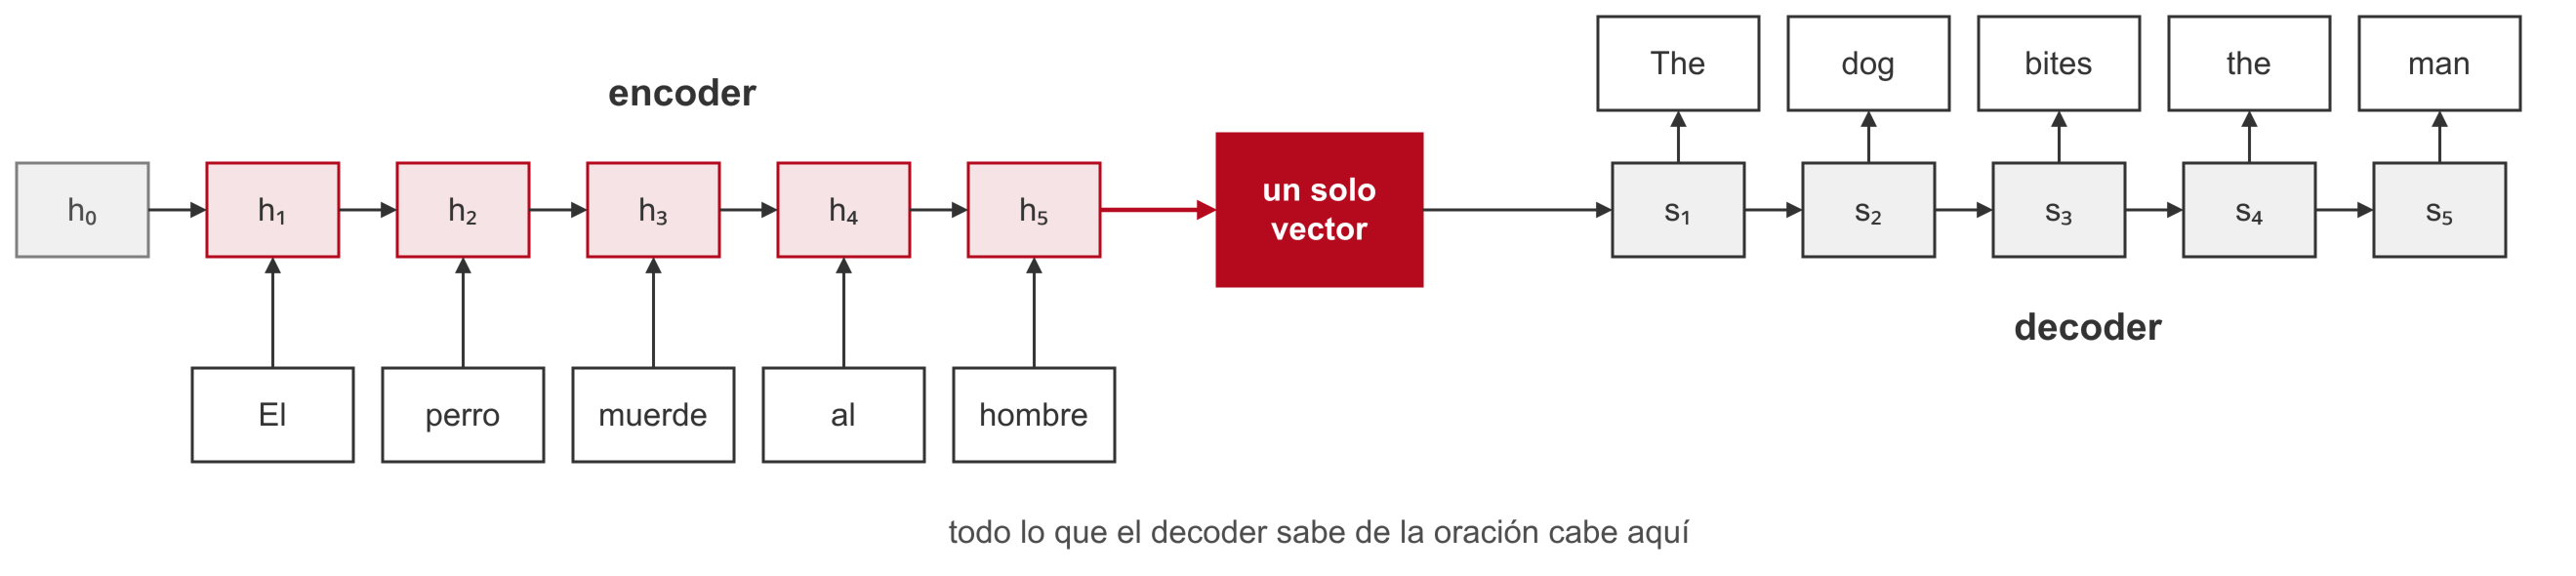

Probemos primero con un problema que podemos entrenar aquí: pasar números escritos en palabras a dígitos. «dos mil veintiséis» son tres palabras y «2026» son cuatro dígitos.

In [20]:
UNIDADES = ("cero uno dos tres cuatro cinco seis siete ocho nueve diez once doce trece catorce "
            "quince dieciséis diecisiete dieciocho diecinueve veinte veintiuno veintidós veintitrés "
            "veinticuatro veinticinco veintiséis veintisiete veintiocho veintinueve").split()
DECENAS = "_ _ _ treinta cuarenta cincuenta sesenta setenta ochenta noventa".split()
CENTENAS = ("_ ciento doscientos trescientos cuatrocientos quinientos seiscientos setecientos "
            "ochocientos novecientos").split()


def hasta_mil(n):
    """Escribe en palabras un número entre 1 y 999."""
    if n == 100:
        return ["cien"]
    palabras = [CENTENAS[n // 100]] if n >= 100 else []
    n %= 100
    if 0 < n < 30:
        palabras.append(UNIDADES[n])
    elif n >= 30:
        palabras += [DECENAS[n // 10]] + (["y", UNIDADES[n % 10]] if n % 10 else [])
    return palabras


def en_palabras(n):
    """Escribe en palabras un número entre 0 y 9.999.999."""
    if n == 0:
        return ["cero"]
    millones, miles, resto = n // 10**6, n // 1000 % 1000, n % 1000
    apocope = {"uno": "un", "veintiuno": "veintiún"}
    palabras = []
    if millones:
        palabras += ["un", "millón"] if millones == 1 else hasta_mil(millones) + ["millones"]
    if miles:
        palabras += ["mil"] if miles == 1 else [apocope.get(p, p) for p in hasta_mil(miles)] + ["mil"]
    return palabras + (hasta_mil(resto) if resto else [])


for n in [16, 342, 2026, 21_000, 1_200_000]:
    print(n, " ".join(en_palabras(n)))

16 dieciséis
342 trescientos cuarenta y dos
2026 dos mil veintiséis
21000 veintiún mil
1200000 un millón doscientos mil


In [21]:
def numero_al_azar():
    """Devuelve un número con una cantidad de dígitos al azar entre 1 y 7."""
    d = random.randint(1, 7)
    return random.randint(10 ** (d - 1) if d > 1 else 0, 10**d - 1)


random.seed(0)
numeros = list({numero_al_azar() for _ in range(45_000)})
random.shuffle(numeros)
pares_prueba = [(en_palabras(n), str(n)) for n in numeros[:2_000]]
pares_entreno = [(en_palabras(n), str(n)) for n in numeros[2_000:]]

palabras_num = ["<pad>"] + sorted({p for ps, _ in pares_entreno for p in ps})
id_palabra = {p: i for i, p in enumerate(palabras_num)}
simbolos = ["<pad>", "<s>", "</s>"] + list("0123456789")


def lote_numeros(pares):
    """Devuelve las palabras como ids y los dígitos con inicio y fin."""
    X = nn.utils.rnn.pad_sequence([torch.tensor([id_palabra[p] for p in ps]) for ps, _ in pares],
                                  batch_first=True)
    Y = nn.utils.rnn.pad_sequence([torch.tensor([1] + [simbolos.index(c) for c in ds] + [2])
                                   for _, ds in pares], batch_first=True)
    return X, Y


len(pares_entreno), pares_entreno[0]

(22527, (['dieciséis', 'mil', 'ciento', 'setenta', 'y', 'ocho'], '16178'))

El modelo son dos GRU. El encoder lee las palabras y entrega su último estado; el decoder parte de ese estado y, en cada paso, recibe el dígito anterior y predice el siguiente. Al entrenar, ese dígito anterior es el correcto y no el que predijo la red: es el *teacher forcing*.

In [22]:
class EncoderDecoder(nn.Module):
    def __init__(self, n_origen, n_destino, d=64, h=128):
        super().__init__()
        self.emb_origen = nn.Embedding(n_origen, d, padding_idx=0)
        self.emb_destino = nn.Embedding(n_destino, d, padding_idx=0)
        self.encoder = nn.GRU(d, h, batch_first=True)
        self.decoder = nn.GRU(d, h, batch_first=True)
        self.salida = nn.Linear(h, n_destino)

    def codificar(self, X):
        largos = (X != 0).sum(1)
        E = nn.utils.rnn.pack_padded_sequence(self.emb_origen(X), largos, batch_first=True,
                                              enforce_sorted=False)
        return self.encoder(E)[1]  # el único vector que pasa al decoder

    def forward(self, X, Y):
        H, _ = self.decoder(self.emb_destino(Y), self.codificar(X))
        return self.salida(H)


def entrenar_numeros(h=128, pasos=1500):
    """Entrena un encoder–decoder de números con un estado de tamaño h."""
    torch.manual_seed(0)
    red = EncoderDecoder(len(palabras_num), len(simbolos), h=h)
    optimizador = torch.optim.Adam(red.parameters(), lr=3e-3)
    for paso_ in range(pasos):
        X, Y = lote_numeros(random.sample(pares_entreno, 128))
        error = nn.functional.cross_entropy(red(X, Y[:, :-1]).flatten(0, 1), Y[:, 1:].flatten(),
                                            ignore_index=0)
        optimizador.zero_grad()
        error.backward()
        nn.utils.clip_grad_norm_(red.parameters(), 1.0)
        optimizador.step()
    return red


random.seed(0)
red_numeros = entrenar_numeros()

Para usarla, el decoder parte del símbolo de inicio y escribe un dígito por vez, cada uno a partir del que acaba de escribir, hasta producir el símbolo de fin.

**Antes de ejecutar:** ¿acertará con un número que no vio al entrenar, como «setecientos cuarenta mil uno»?

In [23]:
def a_digitos(red, palabras, largo_max=10):
    """Escribe los dígitos de un número dado en palabras."""
    red.eval()
    with torch.no_grad():
        h = red.codificar(torch.tensor([[id_palabra[p] for p in palabras]]))
        y, digitos = torch.tensor([[1]]), ""
        for _ in range(largo_max):
            s, h = red.decoder(red.emb_destino(y), h)
            y = red.salida(s).argmax(-1)
            if y.item() == 2:
                break
            digitos += simbolos[y.item()]
    return digitos


for texto in ["setecientos cuarenta mil uno", "dos mil veintiséis", "un millón trescientos mil doce"]:
    print(texto, "→", a_digitos(red_numeros, texto.split()))
aciertos = [a_digitos(red_numeros, ps) == ds for ps, ds in pares_prueba]
sum(aciertos) / len(aciertos)

setecientos cuarenta mil uno → 740001
dos mil veintiséis → 2026
un millón trescientos mil doce → 1300012


0.9735

Con un estado de 128 números acierta casi todos los números de prueba. ¿Qué pasa si el estado es más chico? En el ejercicio 4 entrenamos la misma red con un estado de 16 números; este es el resultado de nuestra ejecución, por cantidad de dígitos:

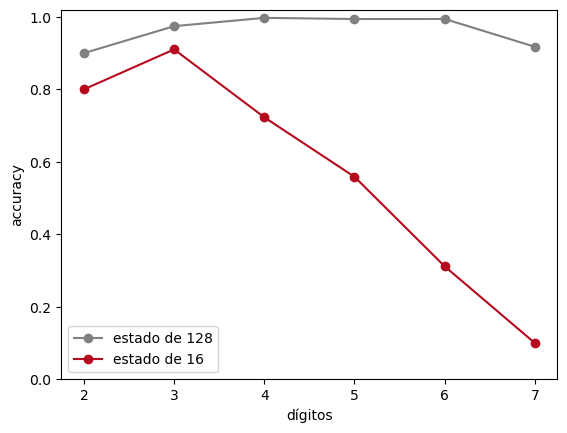

Con el estado chico, los errores se concentran en los números largos: todo lo que el decoder sabe del número tiene que caber en ese vector.

### 4.1 Un traductor

La misma arquitectura, entrenada antes sobre unos 132.000 pares de frases español–inglés de Tatoeba (tatoeba.org, licencia CC BY 2.0 FR, vía manythings.org), con dos GRU de 384 números y sin atención. Tardó 90 segundos en una GPU.

In [24]:
def tokenizar_tr(texto):
    """Devuelve palabras y signos en minúsculas, para traducir."""
    return re.findall(r"\w+(?:'\w+)?|[^\w\s]", texto.lower())


guardado = torch.hub.load_state_dict_from_url(URL_MODELOS + "4-traductor-es-en.pt", weights_only=True)
origen, destino = guardado["origen"], guardado["destino"]
id_origen = {p: i for i, p in enumerate(origen)}
traductor = EncoderDecoder(len(origen), len(destino), guardado["d"], guardado["h"])
traductor.load_state_dict({k: v.float() for k, v in guardado["pesos"].items()})
traductor.eval()


def traducir(frase, largo_max=30):
    """Traduce una frase del español al inglés."""
    with torch.no_grad():
        h = traductor.codificar(torch.tensor([[id_origen.get(p, 3) for p in tokenizar_tr(frase)]]))
        y, palabras = torch.tensor([[1]]), []
        for _ in range(largo_max):
            s, h = traductor.decoder(traductor.emb_destino(y), h)
            y = traductor.salida(s).argmax(-1)
            if y.item() == 2:
                break
            palabras.append(destino[y.item()])
    return " ".join(palabras)


for frase in ["Me gusta el café.", "¿Dónde está la biblioteca?",
              "El perro muerde al hombre.", "El hombre muerde al perro.", "Vino ayer y trajo vino."]:
    print(frase, "→", traducir(frase))

Me gusta el café. → i like coffee .
¿Dónde está la biblioteca? → where's the library ?
El perro muerde al hombre. → the dog chased the man .
El hombre muerde al perro. → the dog bite the dog .
Vino ayer y trajo vino. → he came yesterday and wine .


**Antes de ejecutar:** ¿cómo le irá con oraciones más largas?

In [25]:
for frase in ["Mi hermano trabaja en un banco desde hace cinco años.",
              "Ayer fuimos al cine con mis amigos y después cenamos en un restaurante italiano.",
              "Aunque llovía mucho, decidimos salir a caminar porque necesitábamos aire fresco."]:
    print(frase, "→", traducir(frase))

Mi hermano trabaja en un banco desde hace cinco años. → my brother works in a bank since october .
Ayer fuimos al cine con mis amigos y después cenamos en un restaurante italiano. → we went to the movies with a restaurant yesterday , and i were in college with a restaurant .
Aunque llovía mucho, decidimos salir a caminar porque necesitábamos aire fresco. → although it was raining hard , i decided to get a fresh air .


Con oraciones largas, la traducción sigue sonando a inglés pero pierde contenido. En las 3.000 frases de prueba, medido con BLEU (coincidencia con la traducción de referencia, de 0 a 100):

| Largo de la frase en español (palabras y signos) | 1–4 | 5–7 | 8–10 | 11–14 | 15–20 |
|---|---|---|---|---|---|
| Frases de prueba | 383 | 1.392 | 884 | 287 | 54 |
| BLEU | 51 | 50 | 36 | 25 | 14 |

Cho et al. (2014b) midieron una caída parecida. Sutskever et al. (2014), con un modelo mucho más grande y la oración de entrada invertida, reportaron que el suyo no sufría con oraciones largas: cuánto cae depende del modelo y de los datos. La limitación de fondo es la misma que vimos con los números: todo lo que el decoder sabe de la oración pasa por un solo vector. Bahdanau, Cho y Bengio (2015) propusieron dejar que el decoder mire todos los estados del encoder y elija a cuáles atender en cada palabra. Esa idea, la atención, es el punto de partida de la clase 5.

## 5. Cierre: ¿qué usar y cuándo?

Volvamos a la pregunta de la clase: ¿cómo representamos el orden de las palabras? Con un estado que se actualiza palabra por palabra, que se usa de tres formas:

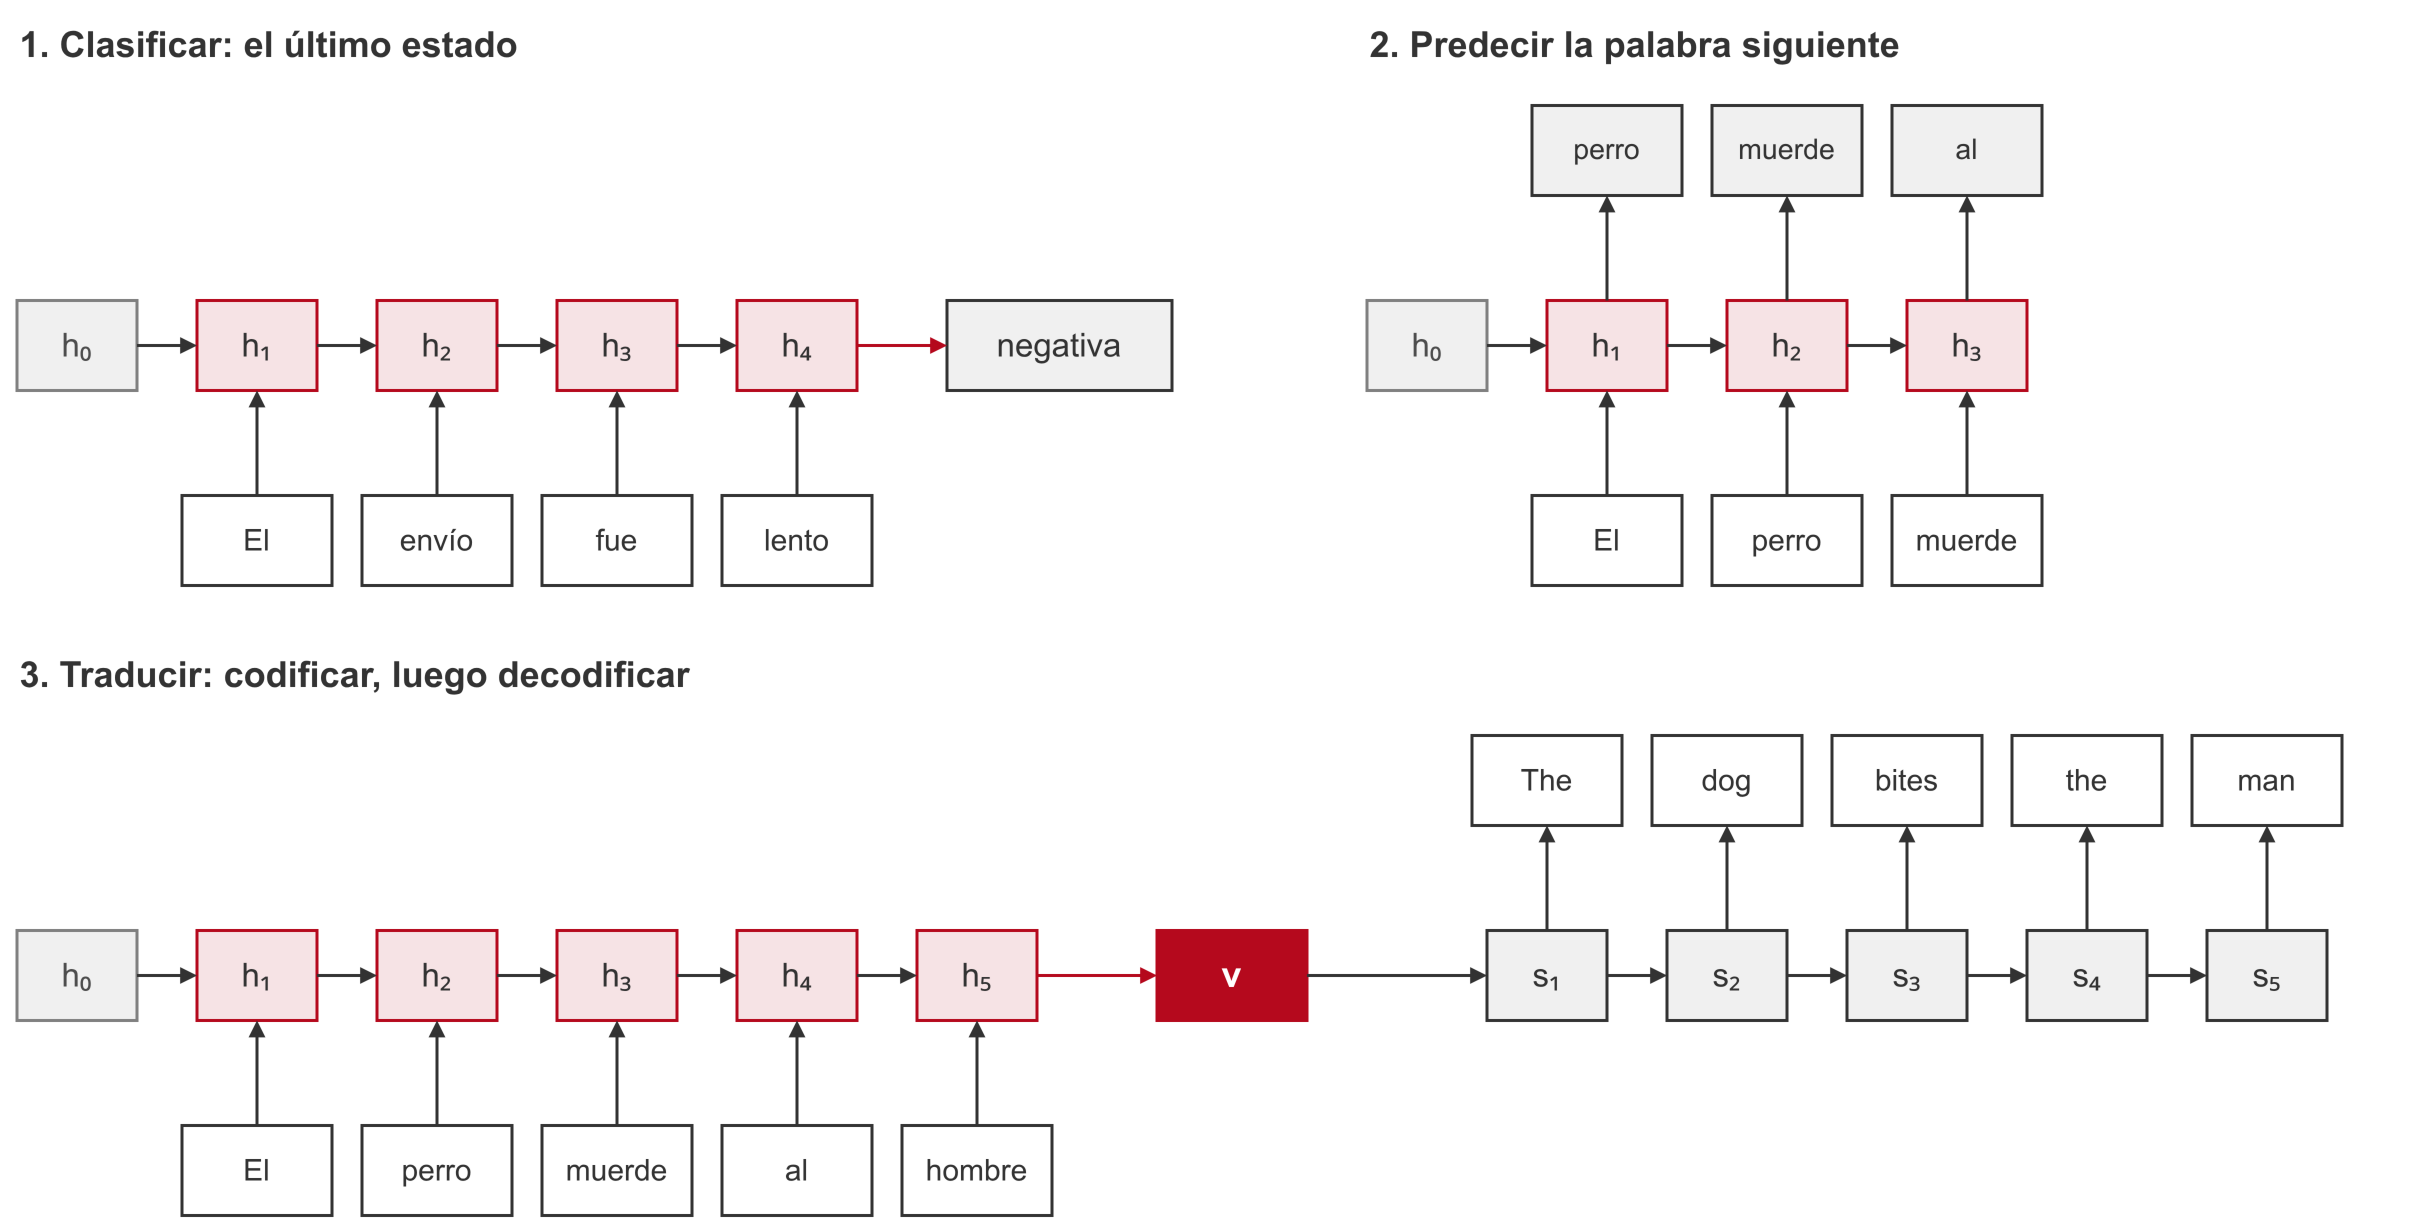

En la práctica:

| Tarea | Qué probar primero |
|---|---|
| Clasificar textos con pocos datos | TF-IDF y regresión logística, como baseline |
| Clasificar cuando el orden importa y hay datos | una GRU o LSTM; desde la clase 5, un modelo preentrenado |
| Una etiqueta por palabra (categorías, entidades) | una red bidireccional, o un modelo preentrenado |
| Texto a texto (traducir, resumir) | un encoder–decoder con atención; hoy, Transformers |
| Texto que llega de a poco (dictado, chat) o un equipo con poca memoria | una GRU o LSTM que lee hacia adelante |

El último estado es un solo vector para todo el texto. Para clasificar alcanza; para traducir oraciones largas, no siempre. La atención resuelve eso, y es el tema de la clase 5.

## Resumen

- Una red recurrente lee una palabra por vez y guarda un estado. En la práctica se usa una GRU o una LSTM, que retienen mejor una pista lejana; en PyTorch se usan como cualquier capa: `nn.GRU`, `nn.LSTM`.
- Un clasificador recurrente es embeddings → GRU → capa lineal sobre el último estado. Hay que guardar los largos (`pack_padded_sequence`) y, para usarlo después, el vocabulario junto con los pesos.
- El orden de trabajo: baseline primero, decisiones con el conjunto de validación (como la mejor época), el conjunto de prueba una sola vez al final y una mirada a los errores.
- Con las reseñas, la GRU empató con TF-IDF y es más grande y más lenta; con los tweets, perdió. La red se justifica cuando el orden cambia la respuesta y hay datos suficientes.
- Con todos los estados se obtiene una salida por palabra; con un encoder y un decoder, una secuencia de otro largo, limitada por el vector que pasa entre los dos.

## Para pensar

- ¿Qué pasaría con el clasificador si no usáramos `pack_padded_sequence` y las reseñas cortas quedaran con muchos ceros al final?
- Con las reseñas, la GRU empata con TF-IDF y tarda más. ¿En qué situación la elegirían igual?
- El etiquetador es bidireccional. ¿Se podría usar uno así para sugerir la palabra siguiente mientras alguien escribe?
- El traductor convierte «El hombre muerde al perro» en otra cosa. ¿Es un problema del cuello de botella, del vocabulario o de los datos de entrenamiento? ¿Cómo lo averiguarían?

## Lecturas

- Jurafsky, D. y Martin, J. H. (2026). *Speech and Language Processing* (3.ª ed., borrador del 19 de agosto de 2026), cap. 14: RNNs and LSTMs. https://web.stanford.edu/~jurafsky/slp3/
- Olah, C. (2015). Understanding LSTM networks. https://colah.github.io/posts/2015-08-Understanding-LSTMs/
- Sutskever, I., Vinyals, O. y Le, Q. V. (2014). Sequence to sequence learning with neural networks. *NeurIPS 2014*.
- Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. y Bengio, Y. (2014). Learning phrase representations using RNN encoder–decoder for statistical machine translation. *EMNLP 2014*, 1724–1734.
- PyTorch, documentación de `torch.nn.GRU`: https://docs.pytorch.org/docs/stable/generated/torch.nn.GRU.html

## Ejercicios propuestos

Para después de la clase. Cada ejercicio supone que ya ejecutaron las celdas de preparación y la sección que se indica. Los que entrenan modelos tardan varios minutos en Colab.

### Ejercicio 1: un paso de GRU a mano

En cada paso, una GRU combina el vector de la palabra actual, $x_t$, con el estado anterior, $h_{t-1}$. Primero calcula dos compuertas, con valores entre 0 y 1 ($\sigma$ es la sigmoide):

$$z_t = \sigma(W_z x_t + U_z h_{t-1}) \qquad r_t = \sigma(W_r x_t + U_r h_{t-1})$$

Con ellas calcula el candidato y el estado nuevo ($\odot$ es el producto componente a componente):

$$\tilde h_t = \tanh\big(W x_t + r_t \odot (U h_{t-1})\big) \qquad h_t = z_t \odot h_{t-1} + (1 - z_t) \odot \tilde h_t$$

La update gate $z_t$ decide cuánto del estado anterior se conserva; la reset gate $r_t$, cuánto del estado anterior entra en el candidato. Las matrices son las mismas en todos los pasos y el estado inicial $h_0$ es un vector de ceros. Omitimos los sesgos.

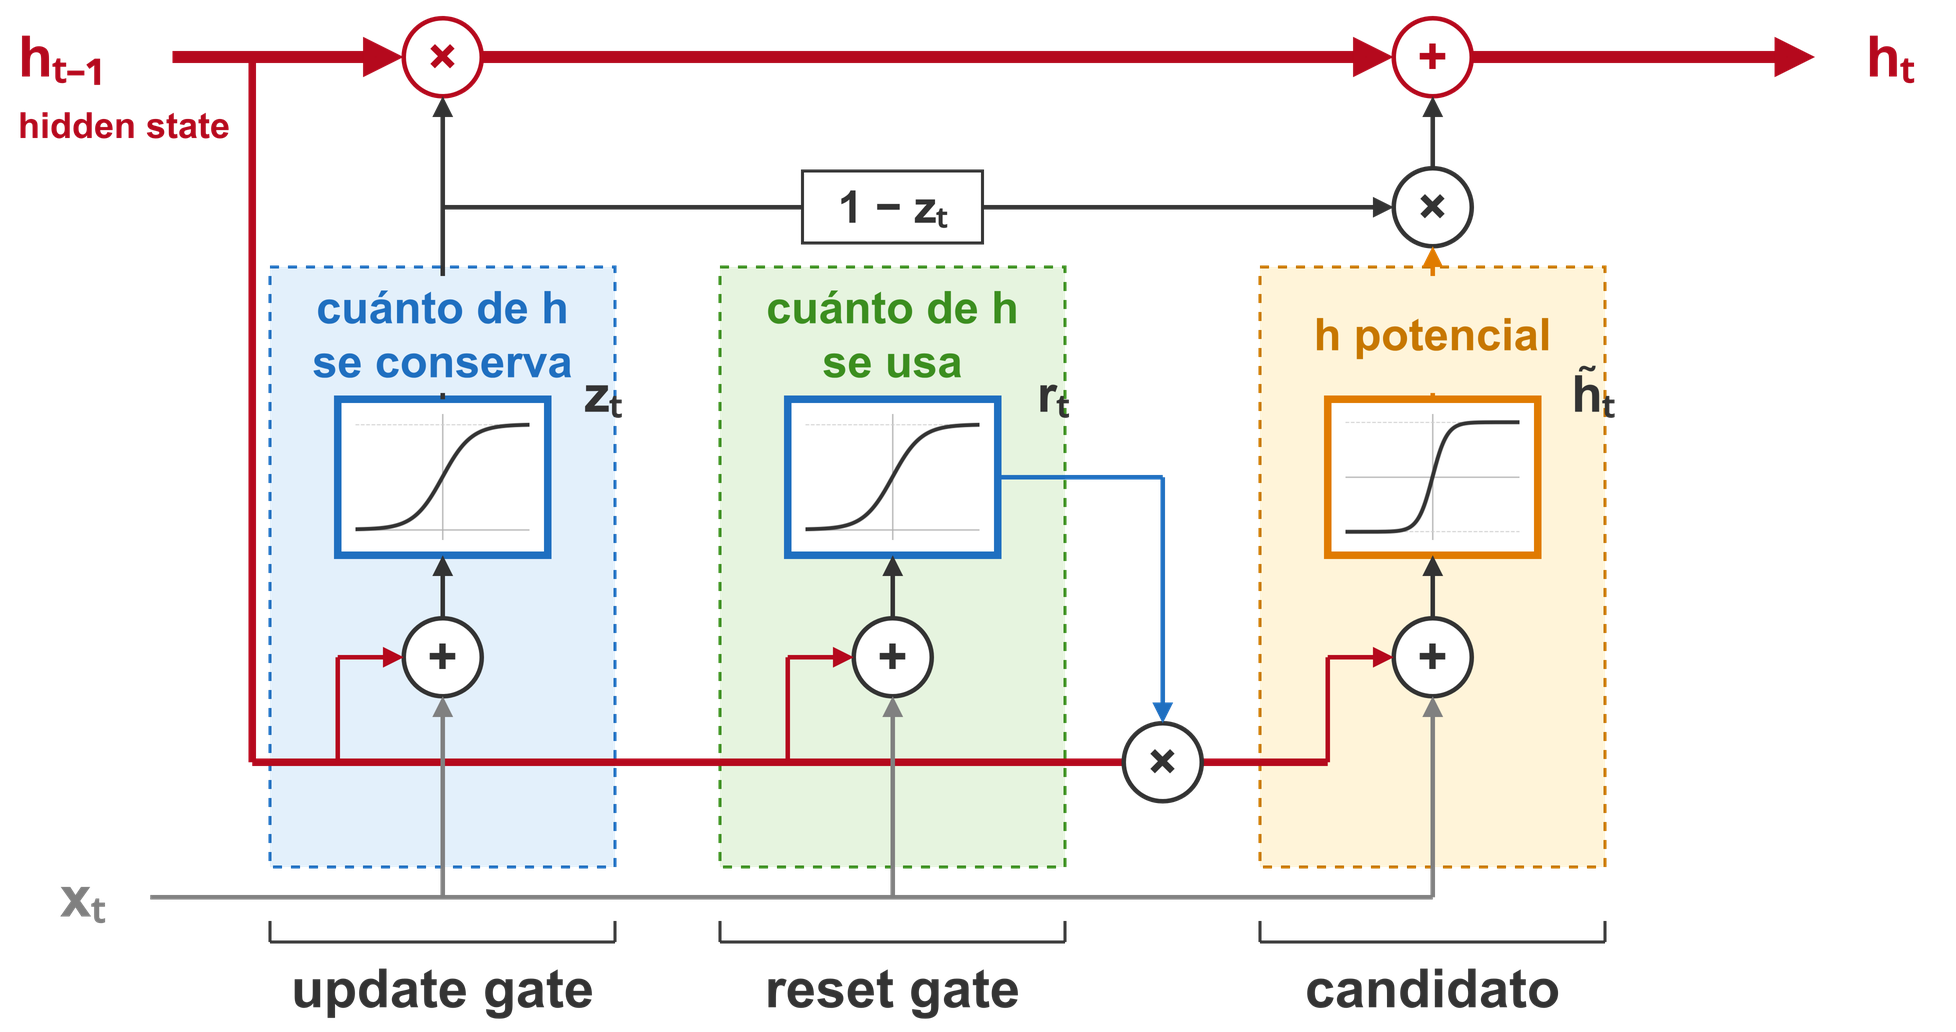

*Diagrama adaptado de Starmer (2022), «Long Short-Term Memory (LSTM), Clearly Explained», StatQuest.*

Para ver los números usamos tres palabras con vectores de dos dimensiones, inventados, y un estado también de dos dimensiones. $W$ es la identidad, así que la palabra entra tal cual al candidato. Elegimos $W_z$ para que la update gate dependa de la palabra: «perro» la deja cerca de 1 y «hombre», cerca de 0. Las matrices de la reset gate son cero, así que $r_t = 0{,}5$ en todos los pasos.

In [26]:
palabras = pd.DataFrame({"perro": [1.0, 0.0],
                         "muerde": [0.5, 0.5],
                         "hombre": [0.0, 1.0]},
                        index=["dim 1", "dim 2"], dtype="float32").T
palabras

,dim 1,dim 2
perro,1.0,0.0
muerde,0.5,0.5
hombre,0.0,1.0


In [27]:
W = torch.eye(2)
U = torch.tensor([[0.5, -0.5],
                  [0.5, 0.5]])
W_z = torch.tensor([[3.0, -3.0],
                    [3.0, -3.0]])
U_z = torch.zeros(2, 2)
W_r = torch.zeros(2, 2)
U_r = torch.zeros(2, 2)


def paso(x: torch.Tensor,
         h: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Devuelve el estado nuevo y la update gate."""
    z = torch.sigmoid(W_z @ x + U_z @ h)
    r = torch.sigmoid(W_r @ x + U_r @ h)
    candidato = torch.tanh(W @ x + r * (U @ h))
    return z * h + (1 - z) * candidato, z

Leemos «perro muerde hombre» palabra por palabra. El bucle `for` es la red recurrente: la misma función `paso`, aplicada tres veces, arrastrando `h`. Mostramos también la update gate de cada paso (sus dos componentes son iguales con esta $W_z$).

In [28]:
def estados(frase: str) -> pd.DataFrame:
    """Devuelve una fila por palabra con el estado y la update gate."""
    h = torch.zeros(2)
    filas = []
    for palabra in frase.split():
        h, z = paso(torch.tensor(palabras.loc[palabra].values), h)
        filas.append([*h.numpy(), z[0].item()])
    return pd.DataFrame(filas, index=frase.split(),
                        columns=["dim 1", "dim 2", "z"])


estados("perro muerde hombre")

,dim 1,dim 2,z
perro,0.04,0.00,0.95
muerde,0.25,0.23,0.50
hombre,0.02,0.78,0.05


Con «perro», $z \approx 0{,}95$: el estado casi no cambia y sigue cerca de $h_0 = 0$. Con «hombre», $z \approx 0{,}05$: el estado se reemplaza casi entero por el candidato.

**Antes de ejecutar:** si leemos «hombre muerde perro», ¿el estado final será el mismo?

In [29]:
estados("hombre muerde perro")

,dim 1,dim 2,z
hombre,0.00,0.73,0.05
muerde,0.15,0.66,0.50
perro,0.18,0.64,0.95


El estado final es distinto: las mismas palabras en otro orden dejan otro estado. Además, como «perro» deja $z \approx 0{,}95$, el estado final conserva casi todo lo que había antes de leerla.

PyTorch trae esta regla en `nn.GRUCell`, que guarda las matrices de cada lado apiladas en el orden $r$, $z$, candidato. Si le copiamos las nuestras, calcula lo mismo.

In [30]:
celda = nn.GRUCell(2, 2)
with torch.no_grad():
    celda.weight_ih.copy_(torch.cat([W_r, W_z, W]))
    celda.weight_hh.copy_(torch.cat([U_r, U_z, U]))
    celda.bias_ih.zero_()
    celda.bias_hh.zero_()

    h = torch.zeros(1, 2)
    for palabra in ["hombre", "muerde", "perro"]:
        h = celda(torch.tensor(palabras.loc[palabra].values)[None], h)
h

tensor([[0.1802, 0.6372]])

Prueben: ¿qué pasa con las dos frases si $W_z$ es la matriz de ceros, de modo que $z = 0{,}5$ en todos los pasos? ¿Y si le cambian el signo?

### Ejercicio 2: los tweets de la Tarea 1

Usa las funciones de la sección 1. Comparamos la GRU con TF-IDF en los tweets, con la misma partición para los dos y con accuracy y macro-F1.

In [31]:
from sklearn.metrics import f1_score

URL_TW = "https://raw.githubusercontent.com/dccuchile/CC6205/master/assignments/new/assignment_1/train/train.tsv"
tweets = pd.read_csv(URL_TW, sep="\t")
tweets["tokens"] = tweets["texto"].map(tokenizar)
tweets = tweets[tweets["tokens"].str.len() > 0]
clases = sorted(tweets["clase"].unique())
tweets["etiqueta"] = tweets["clase"].map(clases.index)
prueba_tw = tweets.sample(frac=0.2, random_state=0)
resto_tw = tweets.drop(prueba_tw.index)
val_tw = resto_tw.sample(frac=0.1, random_state=0)
entreno_tw = resto_tw.drop(val_tw.index)
tweets["clase"].value_counts()

clase
incivilidad    5424
normal         4280
odio           2510
Name: count, dtype: int64

In [32]:
vocab_tw = crear_vocabulario(entreno_tw["tokens"], minimo=2)
torch.manual_seed(0)
modelo_tw = entrenar(Clasificador(len(vocab_tw), salidas=3), lote(entreno_tw, "etiqueta", vocab_tw),
                     lote(val_tw, "etiqueta", vocab_tw), epocas=4)
X_p, L_p, y_p = lote(prueba_tw, "etiqueta", vocab_tw)
with torch.no_grad():
    pred_gru = modelo_tw(X_p, L_p).argmax(1).numpy()

tfidf_tw = TfidfVectorizer(min_df=2)
logistica_tw = LogisticRegression(max_iter=3000).fit(tfidf_tw.fit_transform(entreno_tw["texto"]),
                                                     entreno_tw["etiqueta"])
pred_tfidf = logistica_tw.predict(tfidf_tw.transform(prueba_tw["texto"]))

pd.DataFrame({nombre: {"accuracy": (pred == y_p.numpy()).mean(),
                       "macro-F1": f1_score(y_p.numpy(), pred, average="macro")}
              for nombre, pred in [("GRU", pred_gru), ("TF-IDF", pred_tfidf)]}).T.round(3)

época 1: accuracy de validación 0.559


época 2: accuracy de validación 0.686


época 3: accuracy de validación 0.705


época 4: accuracy de validación 0.722


,accuracy,macro-F1
GRU,0.74,0.72
TF-IDF,0.77,0.75


Prueben mejorar la GRU usando solo el conjunto de validación para decidir: más épocas, un estado más grande, una LSTM o una GRU bidireccional (`bidirectional=True`; el último estado de cada dirección queda en `h[-2]` y `h[-1]`, así que la capa lineal recibe `torch.cat([h[-2], h[-1]], 1)`, de `2 * h` entradas). ¿Llega a TF-IDF? La Tarea 2 vuelve sobre esta comparación.

### Ejercicio 3: entrenar el etiquetador

Usa la clase `Etiquetador` de la sección 3. Entrenamos desde cero la red que cargamos ya entrenada, con menos épocas. Tarda unos minutos.

In [33]:
import urllib.request

URL_UD = "https://raw.githubusercontent.com/UniversalDependencies/UD_Spanish-GSD/master/es_gsd-ud-"


def leer_conllu(parte):
    """Devuelve las oraciones como listas de pares (palabra, categoría)."""
    texto = urllib.request.urlopen(URL_UD + parte + ".conllu").read().decode()
    oraciones = []
    for bloque in texto.strip().split("\n\n"):
        filas = [linea.split("\t") for linea in bloque.split("\n") if not linea.startswith("#")]
        oraciones.append([(f[1].lower(), f[3]) for f in filas if f[0].isdigit()])
    return oraciones


ud_entreno, ud_prueba = leer_conllu("train"), leer_conllu("test")
vocab_et = crear_vocabulario([[p for p, _ in o] for o in ud_entreno], minimo=2)


def lote_et(oraciones):
    """Devuelve las matrices de ids de palabras y de categorías, con relleno."""
    X = nn.utils.rnn.pad_sequence([codificar([p for p, _ in o], vocab_et) for o in oraciones],
                                  batch_first=True)
    Y = nn.utils.rnn.pad_sequence([torch.tensor([categorias.index(c) for _, c in o]) for o in oraciones],
                                  batch_first=True)
    return X, Y


X_et, Y_et = lote_et(ud_entreno)
X_et_p, Y_et_p = lote_et(ud_prueba)
torch.manual_seed(0)
mi_etiquetador = Etiquetador(len(vocab_et), len(categorias))
optimizador = torch.optim.Adam(mi_etiquetador.parameters(), lr=3e-3)
perdida = nn.CrossEntropyLoss(ignore_index=0)
for epoca in range(3):
    for i in torch.randperm(len(X_et)).split(64):
        optimizador.zero_grad()
        perdida(mi_etiquetador(X_et[i]).flatten(0, 1), Y_et[i].flatten()).backward()
        optimizador.step()
    with torch.no_grad():
        pred = mi_etiquetador(X_et_p).argmax(-1)
    reales = Y_et_p != 0
    print(f"época {epoca + 1}: accuracy de prueba {(pred[reales] == Y_et_p[reales]).float().mean():.3f}")

época 1: accuracy de prueba 0.869


época 2: accuracy de prueba 0.910


época 3: accuracy de prueba 0.926


Prueben su etiquetador con oraciones ambiguas («Llama a tu madre», «La llama del fuego», «Bajo la mesa hay un gato»). ¿Qué cambia si la red no es bidireccional?

### Ejercicio 4: el estado del encoder–decoder

Usa las funciones de la sección 4. Entrenamos la red de números con un estado de 16 números y comparamos la accuracy por cantidad de dígitos con la red de 128.

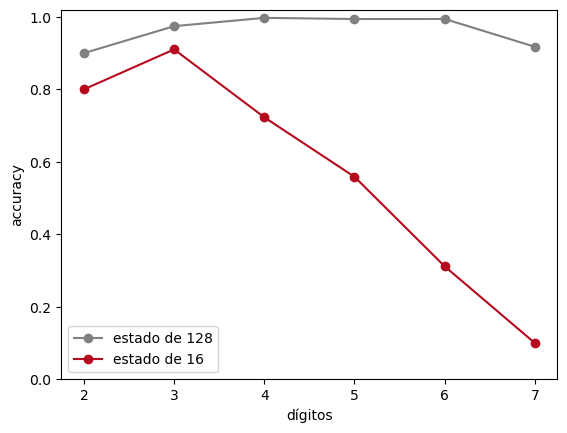

In [34]:
random.seed(0)
red_chica = entrenar_numeros(h=16, pasos=3000)

por_digitos = pd.DataFrame([(len(ds), a_digitos(red_numeros, ps) == ds, a_digitos(red_chica, ps) == ds)
                            for ps, ds in pares_prueba], columns=["dígitos", "estado de 128", "estado de 16"])
por_digitos.groupby("dígitos").mean().plot(marker="o", ylim=(0, 1.02), color=["#808080", "#B5091D"],
                                           ylabel="accuracy");

Prueben con números que la red no vio: por ejemplo, saquen de `pares_entreno` todos los que contienen «setecientos» antes de «mil» y vean si la red los aprende igual.

### Ejercicio 5: un traductor pequeño

Usa `tokenizar_tr` y `EncoderDecoder` de la sección 4. Entrenamos un traductor con 30.000 pares cortos de Tatoeba en CPU, tres épocas (unos minutos), y lo comparamos con el que cargamos.

In [35]:
import io
import urllib.request
import zipfile

pedido = urllib.request.Request("https://www.manythings.org/anki/spa-eng.zip",
                                headers={"User-Agent": "curl/8.5.0", "Accept": "*/*"})
archivo = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(pedido).read()))
filas = [linea.split("\t") for linea in archivo.read("spa.txt").decode().splitlines()]
pares_tr = [(tokenizar_tr(es), tokenizar_tr(en)) for en, es, *_ in filas]
pares_tr = [(o, d) for o, d in pares_tr if len(o) <= 10 and len(d) <= 10]
random.seed(0)
pares_tr = random.sample(pares_tr, 30_000)


def vocab_de(textos, n=6000):
    """Devuelve las n − 4 palabras más frecuentes más los símbolos especiales."""
    frecuencias = Counter(p for t in textos for p in t)
    return ["<pad>", "<s>", "</s>", "<unk>"] + [p for p, _ in frecuencias.most_common(n - 4)]


mi_origen, mi_destino = vocab_de(o for o, _ in pares_tr), vocab_de(d for _, d in pares_tr)
id_mo, id_md = ({p: i for i, p in enumerate(v)} for v in (mi_origen, mi_destino))
X_tr = nn.utils.rnn.pad_sequence([torch.tensor([id_mo.get(p, 3) for p in o]) for o, _ in pares_tr],
                                 batch_first=True)
Y_tr = nn.utils.rnn.pad_sequence([torch.tensor([1] + [id_md.get(p, 3) for p in d] + [2])
                                  for _, d in pares_tr], batch_first=True)

torch.manual_seed(0)
mi_traductor = EncoderDecoder(len(mi_origen), len(mi_destino), d=128, h=256)
optimizador = torch.optim.Adam(mi_traductor.parameters(), lr=2e-3)
for epoca in range(3):
    for i in torch.randperm(len(X_tr)).split(128):
        error = nn.functional.cross_entropy(mi_traductor(X_tr[i], Y_tr[i, :-1]).flatten(0, 1),
                                            Y_tr[i, 1:].flatten(), ignore_index=0)
        optimizador.zero_grad()
        error.backward()
        nn.utils.clip_grad_norm_(mi_traductor.parameters(), 1.0)
        optimizador.step()
    print(f"época {epoca + 1}: pérdida {error.item():.2f}")

época 1: pérdida 3.11


época 2: pérdida 2.58


época 3: pérdida 2.13


Escriban una función como `traducir` para `mi_traductor` (con `id_mo` y `mi_destino`) y comparen sus traducciones con las del traductor cargado. ¿Qué frases le cuestan más?

### Ejercicio 6: RNN, GRU y LSTM en las reseñas

Usa las funciones de la sección 1. Las tres celdas con la misma tabla de embeddings, el mismo tamaño de estado y las mismas tres épocas; tarda unos minutos.

In [36]:
modelos = {}
for celda in [nn.RNN, nn.GRU, nn.LSTM]:
    print(celda.__name__)
    torch.manual_seed(0)
    modelos[celda.__name__] = entrenar(Clasificador(len(vocab), celda),
                                       datos_entreno, datos_val)
pd.Series({nombre: accuracy(m, datos_prueba) for nombre, m in modelos.items()},
          name="accuracy de prueba").round(3)

RNN


época 1: accuracy de validación 0.806


época 2: accuracy de validación 0.777


época 3: accuracy de validación 0.797
GRU


época 1: accuracy de validación 0.891


época 2: accuracy de validación 0.899


época 3: accuracy de validación 0.904
LSTM


época 1: accuracy de validación 0.860


época 2: accuracy de validación 0.897


época 3: accuracy de validación 0.900


RNN     0.80
GRU     0.92
LSTM    0.92
Name: accuracy de prueba, dtype: float64

Ahora, para una reseña con lo bueno al principio y lo malo al final, medimos cuánto mueve cada palabra la probabilidad de reseña positiva (el tamaño del gradiente respecto del vector de cada palabra).

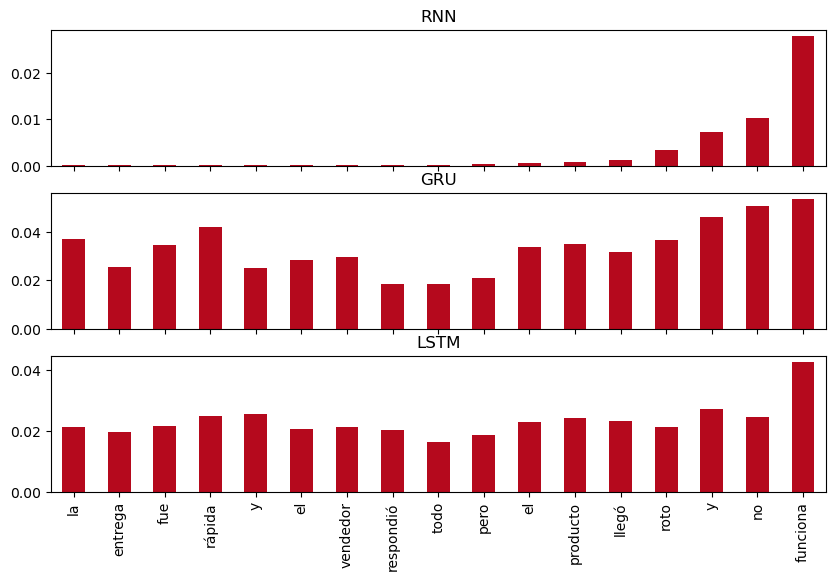

In [37]:
def gradiente_reseña(modelo, texto):
    """Devuelve cuánto mueve cada palabra la probabilidad de reseña positiva."""
    E = modelo.embedding(codificar(tokenizar(texto))[None]).detach().requires_grad_()
    H, _ = modelo.recurrente(E)
    torch.softmax(modelo.salida(H[:, -1]), 1)[0, 1].backward()
    return E.grad[0].norm(dim=1).numpy()


reseña = "La entrega fue rápida y el vendedor respondió todo, pero el producto llegó roto y no funciona"
pd.DataFrame({nombre: gradiente_reseña(m, reseña) for nombre, m in modelos.items()},
             index=tokenizar(reseña)).plot.bar(subplots=True, figsize=(10, 6), legend=False,
                                              color="#B5091D", sharey=False);

¿Hasta qué palabra mira cada modelo para decidir? Comparen con la lectura palabra por palabra de la sección 1.4.